# Unit18_Example_Process_Fault_Diagnosis | 以 GraphSAGE 進行製程故障診斷

本 Notebook 使用經典的 **田納西-伊士曼製程 (Tennessee Eastman Process, TEP)** 資料集，將每個時間點的 52 個製程感測器視為一張**感測器關聯圖**，建立 **GraphSAGE** 圖神經網路模型，進行**圖層級(graph-level)多類別故障分類**。

## 目標
- 認識 GNN 在**製程系統工程**的應用：把感測器網路建模為圖，進行故障診斷
- 學會從**正常operating data的相關性**建立固定拓撲的感測器圖
- 從零實作 **GraphSAGE**（鄰居取樣/聚合）層，並理解「固定拓撲 → 節點對齊 flatten 讀出」與分子圖 pooling 的差異
- 以 GraphSAGE 對 TEP 多種故障進行分類，並與 **MLP、Random Forest** 基線比較
- 透過**感測器失效與雜訊**的穩健性測試，展現 GNN 利用圖結構的獨特優勢

> 本範例是 Unit18 的第三個應用案例。前兩個案例（分子溶解度、分子毒性）都是**分子圖**上的圖層級預測；本案例改用**製程感測器圖**，示範 GNN 在**節點對齊、固定拓撲**情境下的建模方式。

資料背景可參考：[TEP GitHub (Braatz group)](https://github.com/camaramm/tennessee-eastman-profBraatz)、[Downs & Vogel (1993)](https://doi.org/10.1016/0098-1354(93)80018-I)

---
### 0. 環境設定
- 本範例使用已隨課程附帶的 TEP 資料（`data/tep/` 內的 `.dat` 檔）。
- 需要 `networkx` 繪製感測器圖；其餘為標準科學計算套件。

In [1]:
from pathlib import Path
import tensorflow as tf
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P4_Unit18_Example_Process_Fault_Diagnosis'
SOURCE_DATA_DIR = 'tep'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

if IN_COLAB:
    shortcut_path = '/content/ChemE-3590'
    try:
        os.remove(shortcut_path)
    except FileNotFoundError:
        pass
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    NOTEBOOK_DIR = Path(shortcut_path) / 'Part_4' / 'Unit18'
else:
    NOTEBOOK_DIR = Path.cwd()

OUTPUT_DIR = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
DATA_DIR = NOTEBOOK_DIR / 'data' / SOURCE_DATA_DIR
MODEL_DIR = OUTPUT_DIR / 'models'
FIG_DIR = OUTPUT_DIR / 'figs'

for d in (NOTEBOOK_DIR, OUTPUT_DIR, DATA_DIR, MODEL_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"\n✓ Notebook工作目錄: {NOTEBOOK_DIR}")
print(f"✓ 數據來源目錄: {DATA_DIR}")
print(f"✓ 結果輸出目錄: {OUTPUT_DIR}")

# ========================================
# 檢查 GPU 狀態
# ========================================
print(f"\nTensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✓ 偵測到 GPU：{gpus[0].name}")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("△ 未偵測到 GPU，將使用 CPU(本範例資料量小，CPU 即可完成)。")

✓ 偵測到 Local 環境

✓ Notebook工作目錄: D:\MyGit\ChemE-3590\Part_4\Unit18
✓ 數據來源目錄: D:\MyGit\ChemE-3590\Part_4\Unit18\data\tep
✓ 結果輸出目錄: D:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_Example_Process_Fault_Diagnosis

TensorFlow Version: 2.10.1
✓ 偵測到 GPU：/physical_device:GPU:0


---
### 1. 導入必要套件

In [2]:
# 基礎套件
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import warnings
warnings.filterwarnings('ignore')

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, activations, Input, Model

# sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, f1_score)

print(f"TensorFlow版本: {tf.__version__}")
print(f"NumPy版本: {np.__version__}")
print(f"NetworkX版本: {nx.__version__}")

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
plt.rcParams['axes.unicode_minus'] = False

TensorFlow版本: 2.10.1
NumPy版本: 1.26.4
NetworkX版本: 3.4


---
### 2. 載入 TEP 資料與變數說明

**田納西-伊士曼製程 (TEP)** 是化工製程控制與故障診斷領域最經典的基準案例。它模擬一個連續式化學製程，包含反應器、分離器、汽提塔與壓縮機等單元，共量測 **52 個製程變數**：

- `XMEAS(1..41)`：連續與取樣量測（進料流量、反應器溫度/壓力/液位、分離器、汽提塔、成分分析等）
- `XMV(1..11)`：操作變數（各進料閥、冷卻水流量、閥位等）

資料集提供 1 個正常狀態（`d00`）與 21 種預先定義的故障（`d01`~`d21`，即 IDV 1~21）。每個 `.dat` 訓練檔為 480 列、測試檔（`_te`）為 960 列，每列是某個時間點的 52 維觀測向量。

> [!NOTE]
> TEP 原始資料中，正常訓練檔 `d00.dat` 以**轉置**形式儲存（52 列 × 500 行），載入時需轉置回 `(500, 52)`；其餘檔案皆為 `(列數, 52)`。

In [3]:
# 52 個製程變數名稱 (XMEAS 1-41 + XMV 1-11)
XMEAS = ["A Feed", "D Feed", "E Feed", "A+C Feed", "Recycle Flow", "Reactor Feed",
    "Reactor Pressure", "Reactor Level", "Reactor Temp", "Purge Rate",
    "Sep Temp", "Sep Level", "Sep Pressure", "Sep Underflow", "Stripper Level",
    "Stripper Press", "Stripper Underflow", "Stripper Temp", "Stripper Steam",
    "Compressor Work", "Reactor CW Out T", "Sep CW Out T",
    "Rx Feed A", "Rx Feed B", "Rx Feed C", "Rx Feed D", "Rx Feed E", "Rx Feed F",
    "Purge A", "Purge B", "Purge C", "Purge D", "Purge E", "Purge F", "Purge G", "Purge H",
    "Prod D", "Prod E", "Prod F", "Prod G", "Prod H"]
XMV = ["D Feed Flow", "E Feed Flow", "A Feed Flow", "A+C Feed Flow", "Recycle Valve",
       "Purge Valve", "Sep Liq Flow", "Stripper Liq Flow", "Stripper Steam Vlv",
       "Reactor CW Flow", "Condenser CW Flow"]
VARNAMES = XMEAS + XMV
assert len(VARNAMES) == 52

def load_dat(name):
    a = np.loadtxt(DATA_DIR / name)
    if a.shape == (52, 500):      # d00.dat 以轉置形式儲存
        a = a.T
    assert a.shape[1] == 52, (name, a.shape)
    return a

normal_train = load_dat("d00.dat")
print(f"正常訓練資料 d00.dat: {normal_train.shape}  (樣本數 x 變數數)")
print(f"變數數: {len(VARNAMES)} (XMEAS 41 + XMV 11)")

# 以正常資料的平均與標準差做 z-score 標準化基準
mu = normal_train.mean(axis=0)
sigma = normal_train.std(axis=0)
sigma = np.where(sigma < 1e-6, 1.0, sigma)   # 防止常數變數除以 0
def zscore(x):
    return (x - mu) / sigma

正常訓練資料 d00.dat: (500, 52)  (樣本數 x 變數數)
變數數: 52 (XMEAS 41 + XMV 11)


---
### 2.1 選定故障類別並建立「快照圖」資料集

本範例選取 **Normal + 7 種故障** 共 **8 個類別**。選擇時刻意混入不同難度與物理成因的故障，以產生有意義的混淆：

| 類別 | IDV | 說明 | 型態 |
|------|-----|------|------|
| Normal | — | 正常操作 | — |
| F1 | 1 | A/C 進料比例改變 | Step |
| F2 | 2 | B 成分改變 | Step |
| F3 | 3 | D 進料溫度改變 | Step（**難偵測**） |
| F4 | 4 | 反應器冷卻水入口溫度 | Step |
| F8 | 8 | A,B,C 進料成分 | Random |
| F11 | 11 | 反應器冷卻水入口溫度 | Random |
| F14 | 14 | 反應器冷卻水閥卡住 | Sticking |

**關鍵建模概念 — 快照即圖**：我們把**每一個時間點**的 52 個感測器讀數視為**一張圖**（52 個節點），節點特徵為該時刻各變數相對正常基準的標準化偏差。整張圖對應一個故障類別標籤，於是故障診斷變成**圖層級分類**問題。

> [!NOTE]
> 測試檔 `_te.dat` 的故障於第 161 個樣本才導入，故我們只取第 161 列之後（索引 160 起）作為故障樣本；正常類別則使用 `d00.dat` 與 `d00_te.dat` 全部樣本。

In [4]:
FAULTS = [0, 1, 2, 3, 4, 8, 11, 14]
FAULT_NAME = {0: "Normal", 1: "F1 A/C Ratio", 2: "F2 B Comp", 3: "F3 D Feed Temp",
              4: "F4 Rx CW Temp", 8: "F8 Feed Comp", 11: "F11 Rx CW Rand",
              14: "F14 Rx CW Valve"}
NUM_CLASSES = len(FAULTS)
CLASS_LABELS = [FAULT_NAME[f] for f in FAULTS]

allX, allY = [], []
for ci, f in enumerate(FAULTS):
    if f == 0:
        rows = np.vstack([zscore(load_dat("d00.dat")), zscore(load_dat("d00_te.dat"))])
    else:
        rows = np.vstack([zscore(load_dat(f"d{f:02d}.dat")),
                          zscore(load_dat(f"d{f:02d}_te.dat"))[160:]])
    allX.append(rows)
    allY.append(np.full(len(rows), ci))
    print(f"類別 {ci} ({FAULT_NAME[f]:16s}): {len(rows):5d} 個快照")

Xraw = np.vstack(allX).astype(np.float32)     # (B, 52) 標準化後的感測器值
Y = np.concatenate(allY).astype(np.int64)
print(f"\n總圖樣本數 = {Xraw.shape[0]}, 節點數 = {Xraw.shape[1]}, 類別數 = {NUM_CLASSES}")

類別 0 (Normal          ):  1460 個快照
類別 1 (F1 A/C Ratio    ):  1280 個快照
類別 2 (F2 B Comp       ):  1280 個快照
類別 3 (F3 D Feed Temp  ):  1280 個快照
類別 4 (F4 Rx CW Temp   ):  1280 個快照
類別 5 (F8 Feed Comp    ):  1280 個快照
類別 6 (F11 Rx CW Rand  ):  1280 個快照
類別 7 (F14 Rx CW Valve ):  1280 個快照

總圖樣本數 = 10420, 節點數 = 52, 類別數 = 8


### 2.2 故障類別分佈

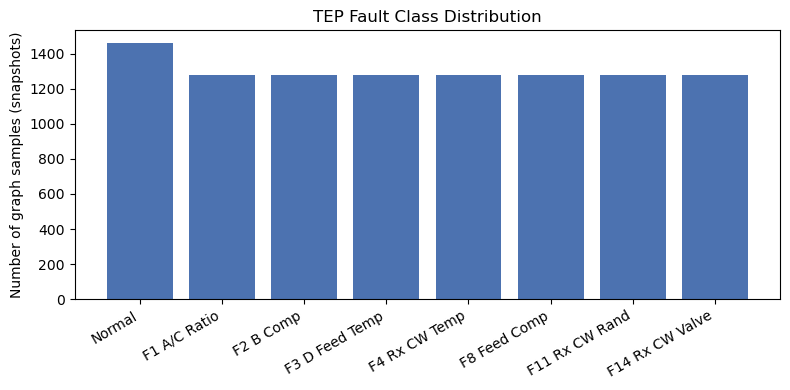

各類別樣本數: {'Normal': 1460, 'F1 A/C Ratio': 1280, 'F2 B Comp': 1280, 'F3 D Feed Temp': 1280, 'F4 Rx CW Temp': 1280, 'F8 Feed Comp': 1280, 'F11 Rx CW Rand': 1280, 'F14 Rx CW Valve': 1280}


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
vals, counts = np.unique(Y, return_counts=True)
ax.bar([CLASS_LABELS[v] for v in vals], counts, color="#4C72B0")
ax.set_ylabel("Number of graph samples (snapshots)")
ax.set_title("TEP Fault Class Distribution")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=120)
plt.show()
print("各類別樣本數:", dict(zip(CLASS_LABELS, counts.tolist())))

---
### 3. 建立感測器關聯圖

GNN 的輸入是圖。製程變數之間存在物理關聯（例如反應器溫度與冷卻水流量、各進料流量與成分），這些關聯會反映在**正常操作資料的相關性**上。我們以正常資料計算 52 個變數兩兩的 **Pearson 相關係數**，取 $|r| \ge 0.25$ 建立無向邊，形成**固定拓撲**的感測器圖（所有快照共用同一張圖，只是節點特徵不同）：

$$
A_{ij} = \begin{cases} 1 & |r_{ij}| \ge 0.25 \text{ 且 } i \ne j \\ 0 & \text{否則} \end{cases}
$$

GraphSAGE 使用**平均聚合器**，因此我們預先計算**列正規化**的鄰接矩陣（每個節點對鄰居取平均）：

$$
\hat{A} = D^{-1} A, \qquad D_{ii} = \sum_j A_{ij}
$$

In [6]:
# 以正常資料計算相關係數矩陣
C = np.nan_to_num(np.corrcoef(zscore(normal_train).T))
THR = 0.25
A = (np.abs(C) >= THR).astype(np.float32)
np.fill_diagonal(A, 0.0)

n_edges = int(A.sum() / 2)
avg_deg = A.sum() / 52
n_isolated = int((A.sum(1) == 0).sum())
print(f"相關性閾值 |r| >= {THR}")
print(f"邊數 = {n_edges}, 平均度 = {avg_deg:.2f}, 孤立節點 = {n_isolated}")

# 列正規化鄰接矩陣 (平均聚合器); 孤立節點除數設 1 避免除以 0
deg = A.sum(1)
deg_safe = np.where(deg == 0, 1.0, deg)
A_norm = (A / deg_safe[:, None]).astype(np.float32)
print(f"A_norm 形狀: {A_norm.shape}")

相關性閾值 |r| >= 0.25
邊數 = 105, 平均度 = 4.04, 孤立節點 = 15
A_norm 形狀: (52, 52)


### 3.1 感測器圖視覺化

下圖左為感測器關聯圖（節點大小/顏色對應其連接度），右為鄰接矩陣。度數高的節點（如反應器與分離器相關變數）是製程中與多個變數強耦合的關鍵感測器。

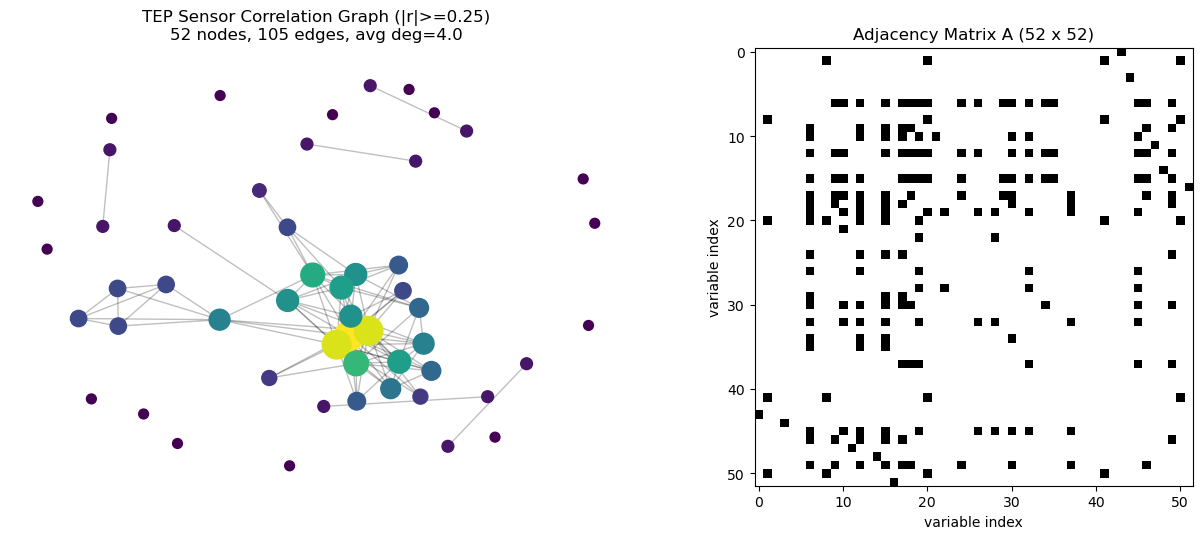

連接度最高的感測器:
  Reactor Pressure     degree=18
  Sep Pressure         degree=17
  Stripper Press       degree=17
  Stripper Temp        degree=12
  Compressor Work      degree=11
  Stripper Steam Vlv   degree=10


In [7]:
G = nx.from_numpy_array(A)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
pos = nx.spring_layout(G, seed=SEED, k=0.6)
degs = np.array([d for _, d in G.degree()])
nx.draw_networkx_nodes(G, pos, node_size=50 + degs * 22, node_color=degs,
                       cmap="viridis", ax=ax1)
nx.draw_networkx_edges(G, pos, alpha=0.25, ax=ax1)
ax1.set_title(f"TEP Sensor Correlation Graph (|r|>={THR})\n"
              f"52 nodes, {n_edges} edges, avg deg={avg_deg:.1f}")
ax1.axis("off")
ax2.imshow(A, cmap="Greys", interpolation="nearest")
ax2.set_title("Adjacency Matrix A (52 x 52)")
ax2.set_xlabel("variable index"); ax2.set_ylabel("variable index")
plt.tight_layout()
plt.savefig(FIG_DIR / "sensor_graph.png", dpi=120)
plt.show()

# 連接度最高的幾個感測器
top = np.argsort(degs)[::-1][:6]
print("連接度最高的感測器:")
for i in top:
    print(f"  {VARNAMES[i]:20s} degree={degs[i]}")

### 3.2 故障特徵 (Fault Signatures)

每種故障會讓**特定子集**的感測器偏離正常值。下圖以 heatmap 顯示各類別每個變數的**平均標準化偏差**（單位：標準差 $\sigma$ ）。可以看到不同故障有不同的「指紋」；而 **F3** 的偏差非常微弱（幾乎與 Normal 無異），正是它難以偵測的原因。

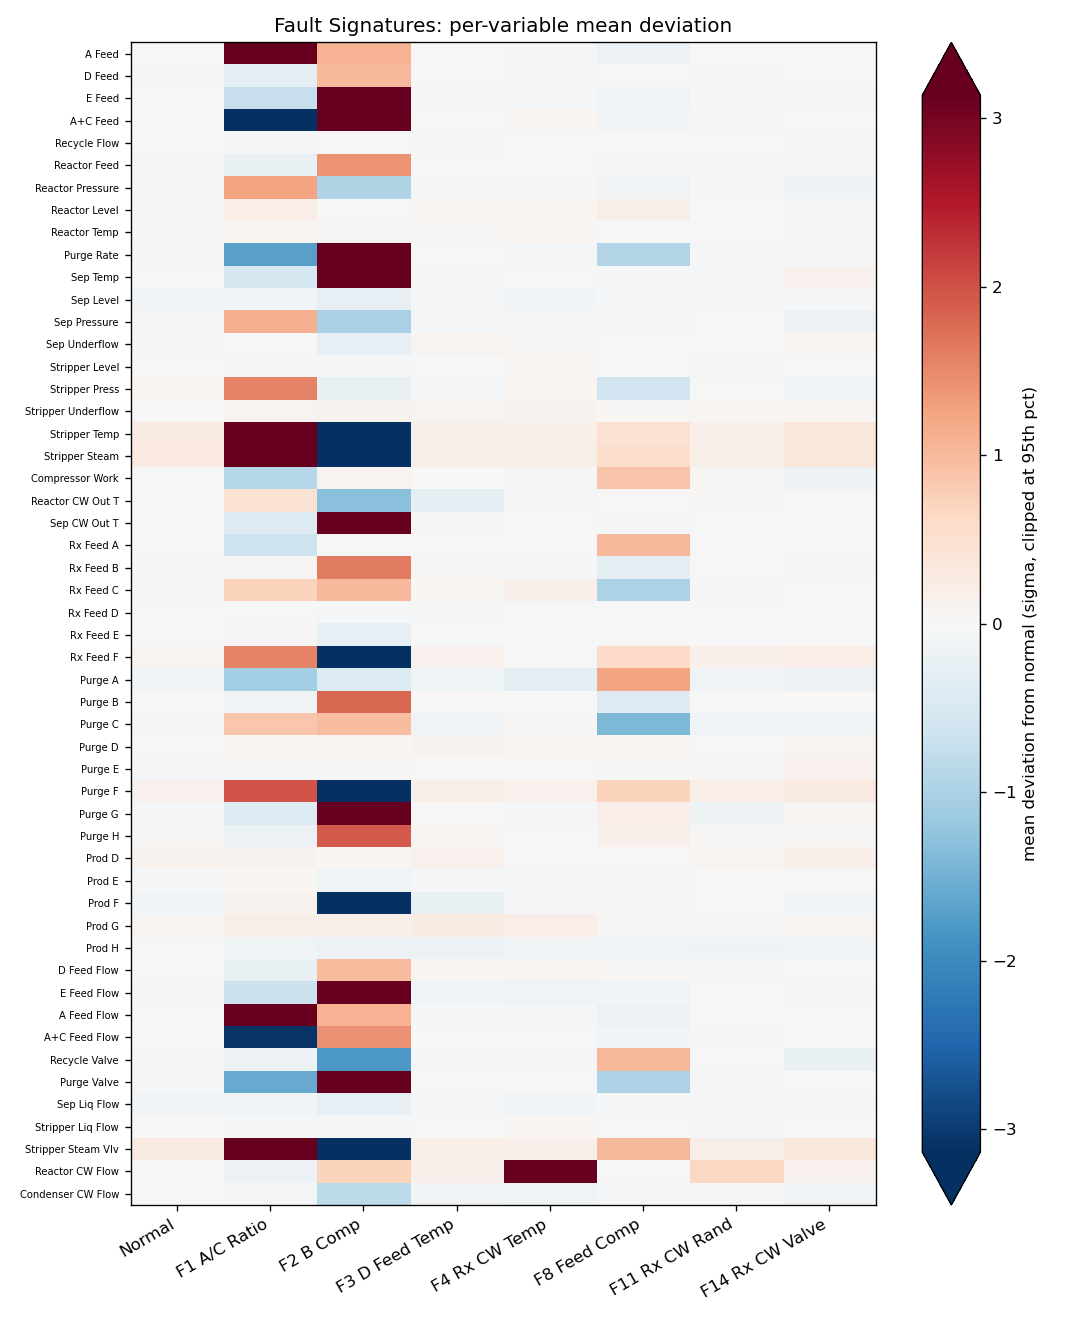

Normal 平均 |偏差| = 0.051 sigma
F3     平均 |偏差| = 0.074 sigma  (難偵測)
F1     平均 |偏差| = 1.684 sigma


In [8]:
sig = np.zeros((52, NUM_CLASSES))
for ci in range(NUM_CLASSES):
    sig[:, ci] = Xraw[Y == ci].mean(0)

fig, ax = plt.subplots(figsize=(9, 11))
vmax = np.percentile(np.abs(sig), 95)   # 穩健上限, 避免 F2 極端值壓縮其他故障色階
im = ax.imshow(sig, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
fig.colorbar(im, ax=ax, label="mean deviation from normal (sigma, clipped at 95th pct)", extend="both")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_LABELS, rotation=30, ha="right")
ax.set_yticks(range(52)); ax.set_yticklabels(VARNAMES, fontsize=6)
ax.set_title("Fault Signatures: per-variable mean deviation")
plt.tight_layout()
plt.savefig(FIG_DIR / "fault_signatures.png", dpi=120)
plt.show()

# F3 與 Normal 的整體偏差幅度比較
print(f"Normal 平均 |偏差| = {np.abs(sig[:, 0]).mean():.3f} sigma")
print(f"F3     平均 |偏差| = {np.abs(sig[:, 3]).mean():.3f} sigma  (難偵測)")
print(f"F1     平均 |偏差| = {np.abs(sig[:, 1]).mean():.3f} sigma")

---
### 4. 節點特徵與資料分割

每個快照圖的節點特徵就是該時刻 52 個變數的標準化值，形狀為 $(52, 1)$ 。以 **80/20 分層抽樣** 分割訓練與測試集；同一組分割同時供 GraphSAGE（圖輸入）與 MLP / Random Forest（攤平輸入）使用，確保公平比較。

In [9]:
X = Xraw[:, :, None]          # (B, 52, 1) 圖輸入: 每個節點 1 維特徵
N, F = X.shape[1], X.shape[2]

idx = np.arange(len(Y))
tr_idx, te_idx = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=Y)
Xtr_g, Xte_g = X[tr_idx], X[te_idx]            # 圖輸入 (., 52, 1)
Xtr, Xte = Xraw[tr_idx], Xraw[te_idx]          # 攤平輸入 (., 52)
ytr, yte = Y[tr_idx], Y[te_idx]

print(f"訓練集: {Xtr_g.shape[0]} 圖, 測試集: {Xte_g.shape[0]} 圖")
print(f"節點特徵形狀: {X.shape[1:]}  (52 節點 x 1 特徵)")

訓練集: 8336 圖, 測試集: 2084 圖
節點特徵形狀: (52, 1)  (52 節點 x 1 特徵)


---
### 5. 從零實作 GraphSAGE 層

**GraphSAGE**（Hamilton et al., 2017）的核心是「**取樣並聚合(Sample and Aggregate)**」。對每個節點 $v$ ，先聚合鄰居的表示，再與自身表示**串接(concatenate)**後做線性轉換：

$$
h_v' = \sigma\left( W \cdot \mathrm{CONCAT}\big(h_v,\; \mathrm{AGG}_{u \in \mathcal{N}(v)} h_u\big) + b \right)
$$

本範例使用**平均聚合器(mean aggregator)**，即 $\mathrm{AGG} = \frac{1}{|\mathcal{N}(v)|}\sum_{u} h_u$ ，可用列正規化鄰接矩陣 $\hat{A}$ 一次算出整張圖所有節點的鄰居平均。

> [!IMPORTANT]
> **GraphSAGE 與 GCN 的關鍵差異**：GCN 把自身與鄰居**一起**做對稱正規化加總；GraphSAGE 則把自身表示與鄰居聚合**分開後串接**，再轉換。這讓節點更能保留「自己的資訊」，並支援**歸納式(inductive)** 學習（可泛化到未見過的節點/圖）。

In [10]:
class GraphSAGELayer(layers.Layer):
    # GraphSAGE (mean aggregator): H' = act( [H ; A_norm @ H] @ W + b )
    def __init__(self, units, A_norm, activation="relu", **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.A = tf.constant(A_norm, dtype=tf.float32)   # 固定拓撲鄰接矩陣
        self.act = activations.get(activation)

    def build(self, input_shape):
        Fin = int(input_shape[-1])
        self.W = self.add_weight("W", (2 * Fin, self.units),
                                 initializer="glorot_uniform")
        self.b = self.add_weight("b", (self.units,), initializer="zeros")

    def call(self, x):                                   # x: (B, N, F)
        neigh = tf.einsum("ij,bjf->bif", self.A, x)      # 鄰居平均 (B, N, F)
        h = tf.concat([x, neigh], axis=-1)               # 串接自身與鄰居 (B, N, 2F)
        return self.act(tf.matmul(h, self.W) + self.b)   # (B, N, units)

print("GraphSAGELayer 已定義。")

GraphSAGELayer 已定義。


---
### 6. 建立 GraphSAGE 分類模型

堆疊兩層 GraphSAGE，讓每個感測器節點聚合**兩跳(2-hop)** 鄰域的資訊。之後進行**讀出(Readout)**，將 52 個節點的表示彙整成單一圖向量，再接 MLP 輸出 8 類別的機率。

> [!TIP]
> **讀出方式的選擇是本範例與分子範例的關鍵差異**：
> - 分子圖**大小不一、節點無對應關係**，必須用**排列不變的 pooling**（如 mean/max pooling）。
> - 本範例的感測器圖是**固定拓撲、節點一一對應**（節點 9 永遠是反應器溫度）。因此我們可以用 **flatten 讀出**（直接攤平 52 個節點的表示），**保留每個感測器的身分資訊** —— 這對「哪個感測器異常」至關重要。這是一個常見於感測器網路、交通網路等**固定圖**任務的設計。

In [11]:
def build_graphsage(hidden=64):
    inp = Input((N, F))
    h = GraphSAGELayer(hidden, A_norm)(inp)      # 第 1 跳
    h = GraphSAGELayer(hidden, A_norm)(h)        # 第 2 跳
    g = layers.Flatten()(h)                      # 固定拓撲 -> 節點對齊 flatten 讀出
    g = layers.Dense(64, activation="relu")(g)
    g = layers.Dropout(0.3)(g)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(g)
    m = Model(inp, out, name="GraphSAGE_fault_classifier")
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

sage = build_graphsage()
sage.summary()

Model: "GraphSAGE_fault_classifier"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 input_1 (InputLayer)        [(None, 52, 1)]           0         


 graph_sage_layer (GraphSAGE  (None, 52, 64)           192       


 Layer)                                                          


... (6 outputs left out)

Total params: 222,024


Trainable params: 222,024


Non-trainable params: 0


_________________________________________________________________


---
### 7. 訓練模型

以交叉熵損失訓練，使用 EarlyStopping（監看驗證損失）避免過擬合並還原最佳權重。

In [12]:
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                   restore_best_weights=True)
history = sage.fit(Xtr_g, ytr, validation_split=0.2, epochs=120,
                   batch_size=64, callbacks=[es], verbose=0)
print(f"訓練完成，共 {len(history.history['loss'])} 個 epoch")
print(f"最終訓練準確率 = {history.history['accuracy'][-1]:.4f}, "
      f"驗證準確率 = {history.history['val_accuracy'][-1]:.4f}")

訓練完成，共 25 個 epoch
最終訓練準確率 = 0.9585, 驗證準確率 = 0.8993


### 7.1 訓練曲線

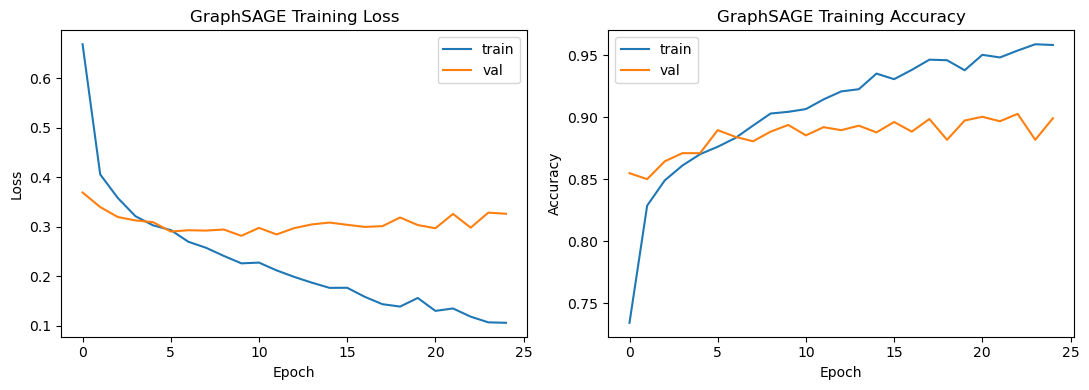

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["loss"], label="train")
axes[0].plot(history.history["val_loss"], label="val")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].set_title("GraphSAGE Training Loss"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="train")
axes[1].plot(history.history["val_accuracy"], label="val")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("GraphSAGE Training Accuracy"); axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "training_curves.png", dpi=120)
plt.show()

---
### 8. 評估與混淆矩陣

在測試集上評估 GraphSAGE，輸出每個類別的 precision / recall / f1，並繪製混淆矩陣。

In [14]:
sage_pred = sage.predict(Xte_g, verbose=0).argmax(1)
sage_acc = accuracy_score(yte, sage_pred)
sage_f1 = f1_score(yte, sage_pred, average="macro")
print(f"GraphSAGE 測試準確率 = {sage_acc:.4f}, macro-F1 = {sage_f1:.4f}\n")
print(classification_report(yte, sage_pred, target_names=CLASS_LABELS, digits=3))

GraphSAGE 測試準確率 = 0.8896, macro-F1 = 0.8933

                 precision    recall  f1-score   support

         Normal      0.691     0.712     0.702       292
   F1 A/C Ratio      0.996     0.996     0.996       256
      F2 B Comp      1.000     0.977     0.988       256
 F3 D Feed Temp      0.682     0.688     0.685       256
  F4 Rx CW Temp      0.925     0.961     0.943       256
   F8 Feed Comp      0.988     0.984     0.986       256
 F11 Rx CW Rand      0.887     0.828     0.857       256
F14 Rx CW Valve      0.985     0.996     0.990       256

       accuracy                          0.890      2084
      macro avg      0.894     0.893     0.893      2084
   weighted avg      0.891     0.890     0.890      2084



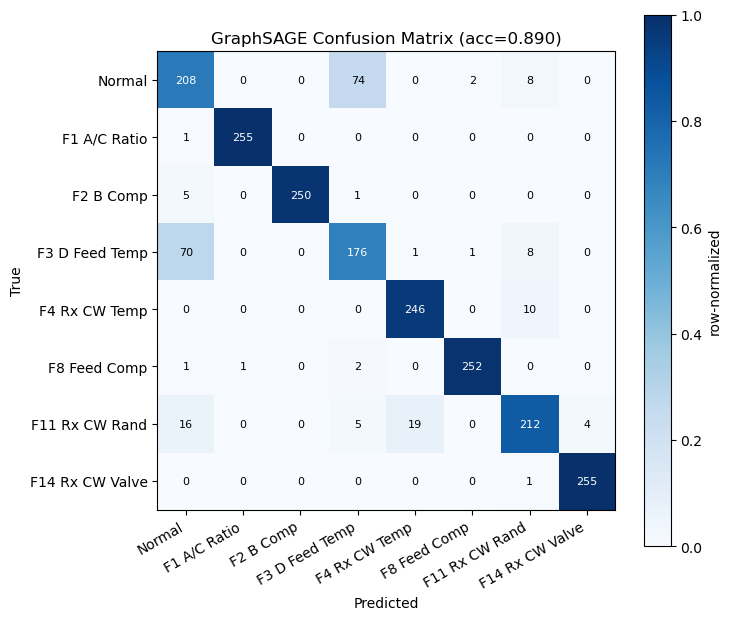

In [15]:
cm = confusion_matrix(yte, sage_pred)
cmn = cm.astype(float) / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="row-normalized")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black", fontsize=8)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_LABELS, rotation=30, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_LABELS)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"GraphSAGE Confusion Matrix (acc={sage_acc:.3f})")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=120)
plt.show()

---
### 8.1 基線比較：MLP 與 Random Forest

為了解 GNN 是否真正帶來價值，我們在**相同分割**上比較三種模型：

1. **GraphSAGE**（本範例，使用感測器圖結構）
2. **MLP**：把 52 個感測器值攤平直接輸入全連接網路（**忽略圖結構**）
3. **Random Forest**：對 52 個感測器值的樹集成分類器（強力的傳統表格基線）

In [16]:
# MLP (攤平輸入, 忽略圖結構)
mlp = keras.Sequential([
    Input((N,)),
    layers.Dense(128, activation="relu"), layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
mlp.compile(optimizer=keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mlp.fit(Xtr, ytr, validation_split=0.2, epochs=120, batch_size=64,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                   restore_best_weights=True)], verbose=0)
mlp_pred = mlp.predict(Xte, verbose=0).argmax(1)
mlp_acc = accuracy_score(yte, mlp_pred)
mlp_f1 = f1_score(yte, mlp_pred, average="macro")

# Random Forest
rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
rf.fit(Xtr, ytr)
rf_pred = rf.predict(Xte)
rf_acc = accuracy_score(yte, rf_pred)
rf_f1 = f1_score(yte, rf_pred, average="macro")

print(f"GraphSAGE     : acc={sage_acc:.4f}  macro-F1={sage_f1:.4f}  params={sage.count_params()}")
print(f"MLP (flatten) : acc={mlp_acc:.4f}  macro-F1={mlp_f1:.4f}  params={mlp.count_params()}")
print(f"Random Forest : acc={rf_acc:.4f}  macro-F1={rf_f1:.4f}")

GraphSAGE     : acc=0.8896  macro-F1=0.8933  params=222024
MLP (flatten) : acc=0.8834  macro-F1=0.8887  params=15560
Random Forest : acc=0.9410  macro-F1=0.9421


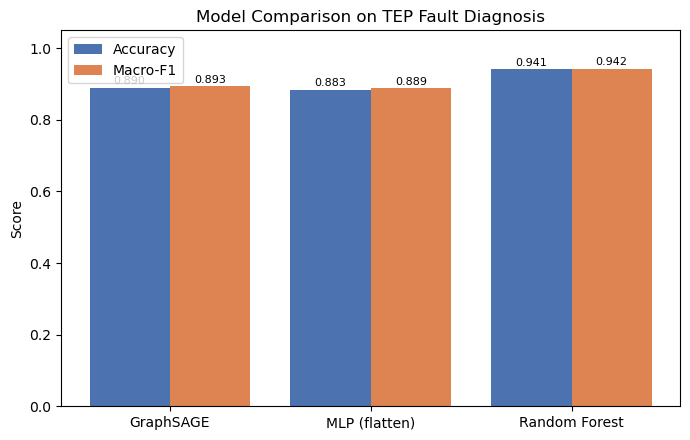

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))
names = ["GraphSAGE", "MLP (flatten)", "Random Forest"]
accs = [sage_acc, mlp_acc, rf_acc]
f1s = [sage_f1, mlp_f1, rf_f1]
xx = np.arange(len(names))
ax.bar(xx - 0.2, accs, 0.4, label="Accuracy", color="#4C72B0")
ax.bar(xx + 0.2, f1s, 0.4, label="Macro-F1", color="#DD8452")
for i, (a, fscore) in enumerate(zip(accs, f1s)):
    ax.text(i - 0.2, a + 0.01, f"{a:.3f}", ha="center", fontsize=8)
    ax.text(i + 0.2, fscore + 0.01, f"{fscore:.3f}", ha="center", fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(names); ax.set_ylim(0, 1.05)
ax.set_ylabel("Score"); ax.set_title("Model Comparison on TEP Fault Diagnosis")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "model_comparison.png", dpi=120)
plt.show()

> [!NOTE]
> 在**乾淨資料**上，**Random Forest 這類樹集成往往是 TEP 表格式故障分類的強力基線**，誠實地說，GraphSAGE 在乾淨準確率上並不一定勝過它。GraphSAGE 明顯**優於同為神經網路的 MLP**，且其真正價值會在下一節的**穩健性測試**中展現。

### 8.2 學習到的圖嵌入 (t-SNE)

把 GraphSAGE 讀出後、分類層之前的圖向量（分類頭的 64 維表示）以 t-SNE 投影到 2D。若同類別聚成簇、不同類別分開，代表模型學到了可分辨的故障表示。

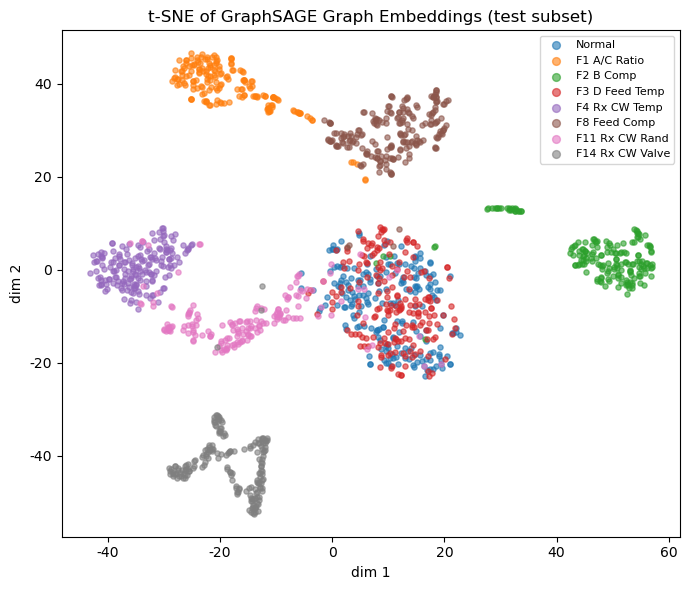

In [18]:
emb_model = Model(sage.input, sage.layers[-3].output)   # Dense(64) 之輸出
emb = emb_model.predict(Xte_g, verbose=0)
sub = np.random.RandomState(SEED).choice(len(emb), size=min(1500, len(emb)), replace=False)
E2 = TSNE(n_components=2, random_state=SEED, perplexity=30, init="pca").fit_transform(emb[sub])

fig, ax = plt.subplots(figsize=(7, 6))
for ci in range(NUM_CLASSES):
    sel = yte[sub] == ci
    ax.scatter(E2[sel, 0], E2[sel, 1], s=14, label=CLASS_LABELS[ci], alpha=0.6)
ax.legend(fontsize=8, markerscale=1.5)
ax.set_title("t-SNE of GraphSAGE Graph Embeddings (test subset)")
ax.set_xlabel("dim 1"); ax.set_ylabel("dim 2")
plt.tight_layout()
plt.savefig(FIG_DIR / "embedding_tsne.png", dpi=120)
plt.show()

---
### 9. 穩健性測試：感測器雜訊與失效

工業現場的感測器常會**老化、產生雜訊、甚至失效(讀數遺失)**。GNN 的鄰居聚合機制理論上能**從相關的鄰近感測器重建被破壞的資訊**，因此對感測器劣化應更穩健。我們用訓練好的三個模型，在**逐步破壞的測試集**上評估：

- **感測器雜訊**：對每個感測器讀數加上不同強度的高斯雜訊（以 $\sigma$ 為單位）
- **感測器失效**：隨機將一定比例的感測器讀數設為 0（模擬訊號遺失）

In [19]:
def eval_all(Xc):
    s = accuracy_score(yte, sage.predict(Xc[:, :, None], verbose=0).argmax(1))
    m = accuracy_score(yte, mlp.predict(Xc, verbose=0).argmax(1))
    r = accuracy_score(yte, rf.predict(Xc))
    return s, m, r

rng = np.random.RandomState(SEED)
noise_levels = [0.0, 0.5, 1.0, 1.5, 2.0]
drop_levels = [0.0, 0.1, 0.2, 0.3, 0.4]
noise_res, drop_res = [], []
for s in noise_levels:
    Xc = Xte + rng.normal(0, s, Xte.shape).astype(np.float32) if s > 0 else Xte
    noise_res.append(eval_all(Xc))
for p in drop_levels:
    Xc = Xte.copy()
    if p > 0:
        Xc[rng.rand(*Xc.shape) < p] = 0.0
    drop_res.append(eval_all(Xc))
noise_res = np.array(noise_res); drop_res = np.array(drop_res)

print("感測器雜訊 (sigma) : SAGE / MLP / RF")
for lv, row in zip(noise_levels, noise_res):
    print(f"  noise={lv:>3}: {row[0]:.3f} / {row[1]:.3f} / {row[2]:.3f}")
print("\n感測器失效 (比例)  : SAGE / MLP / RF")
for lv, row in zip(drop_levels, drop_res):
    print(f"  drop={lv:>4}: {row[0]:.3f} / {row[1]:.3f} / {row[2]:.3f}")

感測器雜訊 (sigma) : SAGE / MLP / RF
  noise=0.0: 0.890 / 0.883 / 0.941
  noise=0.5: 0.859 / 0.862 / 0.884
  noise=1.0: 0.813 / 0.807 / 0.832
  noise=1.5: 0.751 / 0.738 / 0.732
  noise=2.0: 0.700 / 0.666 / 0.638

感測器失效 (比例)  : SAGE / MLP / RF
  drop= 0.0: 0.890 / 0.883 / 0.941
  drop= 0.1: 0.847 / 0.824 / 0.891
  drop= 0.2: 0.801 / 0.758 / 0.831
  drop= 0.3: 0.749 / 0.684 / 0.772
  drop= 0.4: 0.687 / 0.604 / 0.716


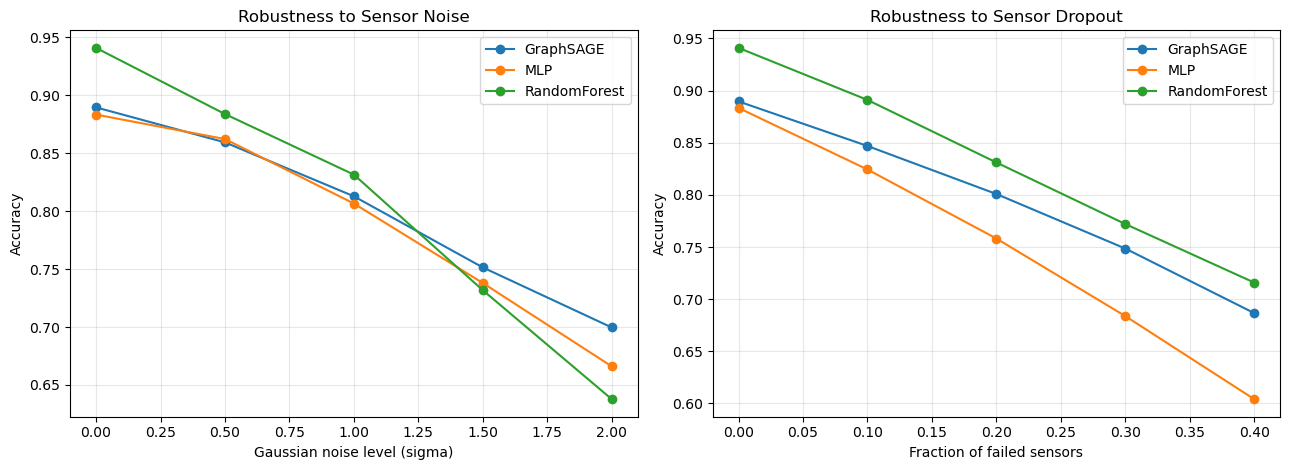

感測器失效 40% 時: GraphSAGE=0.687  MLP=0.604  (GraphSAGE 領先 MLP +0.083)


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for k, name in enumerate(["GraphSAGE", "MLP", "RandomForest"]):
    axes[0].plot(noise_levels, noise_res[:, k], marker="o", label=name)
    axes[1].plot(drop_levels, drop_res[:, k], marker="o", label=name)
axes[0].set_xlabel("Gaussian noise level (sigma)"); axes[0].set_ylabel("Accuracy")
axes[0].set_title("Robustness to Sensor Noise"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_xlabel("Fraction of failed sensors"); axes[1].set_ylabel("Accuracy")
axes[1].set_title("Robustness to Sensor Dropout"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "robustness.png", dpi=120)
plt.show()

print(f"感測器失效 40% 時: GraphSAGE={drop_res[-1,0]:.3f}  MLP={drop_res[-1,1]:.3f}  "
      f"(GraphSAGE 領先 MLP {drop_res[-1,0]-drop_res[-1,1]:+.3f})")

> [!IMPORTANT]
> **這才是 GNN 在此任務的真正價值**：隨著感測器失效比例上升，**GraphSAGE 與 MLP 的差距持續拉大** —— GraphSAGE 透過感測器圖的鄰居聚合，能用**相關的鄰近感測器**補償遺失的讀數，而只看攤平輸入的 MLP 無此能力。在高雜訊下，兩個神經網路模型也會反超 Random Forest。這說明：模型的選擇要看**部署情境**，而非只看乾淨資料上的準確率。

---
### 10. 模型儲存

In [21]:
weights_path = MODEL_DIR / "graphsage_tep_fault"
sage.save_weights(str(weights_path))
np.save(MODEL_DIR / "adjacency.npy", A)
print(f"✓ GraphSAGE 權重已儲存: {weights_path}")
print(f"✓ 感測器圖鄰接矩陣已儲存: {MODEL_DIR / 'adjacency.npy'}")

✓ GraphSAGE 權重已儲存: D:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_Example_Process_Fault_Diagnosis\models\graphsage_tep_fault
✓ 感測器圖鄰接矩陣已儲存: D:\MyGit\ChemE-3590\Part_4\Unit18\outputs\P4_Unit18_Example_Process_Fault_Diagnosis\models\adjacency.npy


---
### 11. 總結

本 Notebook 以經典的 **田納西-伊士曼製程 (TEP)** 資料，示範了 GNN 在**製程系統工程**的應用 —— **把感測器網路建模為圖，進行圖層級故障診斷**：

1. **快照即圖**：每個時間點的 52 個感測器讀數構成一張固定拓撲的圖，故障診斷化為圖層級分類。
2. **從相關性建圖**：以正常操作資料的變數相關性 ( $|r| \ge 0.25$ ) 建立感測器關聯圖。
3. **GraphSAGE**：以「鄰居平均聚合 + 自身串接」的方式更新節點表示；因圖為**固定拓撲、節點對齊**，採用保留感測器身分的 **flatten 讀出**（與分子圖的 pooling 讀出形成對比）。
4. **誠實的基線比較**：乾淨資料上 Random Forest 仍是強力基線；GraphSAGE 優於 MLP，但不必然勝過樹集成。
5. **穩健性才是關鍵優勢**：在**感測器失效/雜訊**情境下，GraphSAGE 透過圖結構補償劣化資訊，**顯著優於 MLP**，展現 GNN 利用製程拓撲的價值。

**與前兩個分子範例的對照**：

| 面向 | 案例一/二 (分子) | 案例三 (製程) |
|------|-----------------|---------------|
| 圖的種類 | 分子圖（原子-鍵） | 感測器關聯圖 |
| 拓撲 | 每個分子不同、大小不一 | 固定、節點一一對應 |
| 讀出方式 | 排列不變 pooling | 節點對齊 flatten |
| 架構 | GCN / GAT | GraphSAGE |
| 任務 | 溶解度回歸 / 毒性分類 | 多類別故障診斷 |

> [!TIP]
> **延伸方向**：(1) 用製程流程圖(PFD)的物理連接取代相關性建圖；(2) 改為**節點層級**任務做故障根因定位（哪個感測器先異常）；(3) 結合時間窗與 GNN（時空圖網路 ST-GNN）捕捉故障的動態演化。